In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

df=pd.read_pickle("./WM811K.pkl")
df.tail()

,dieSize,failureType,lotName,trainTestLabel,waferIndex,waferMap
811452,600.0,Edge-Ring,lot47542,Test,23.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,..."
811453,600.0,Edge-Loc,lot47542,Test,24.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1,..."
811454,600.0,Edge-Ring,lot47542,Test,25.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,..."
811455,600.0,"[0, 0]",lot47543,"[0, 0]",1.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,..."
811456,600.0,"[0, 0]",lot47543,"[0, 0]",2.0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,..."


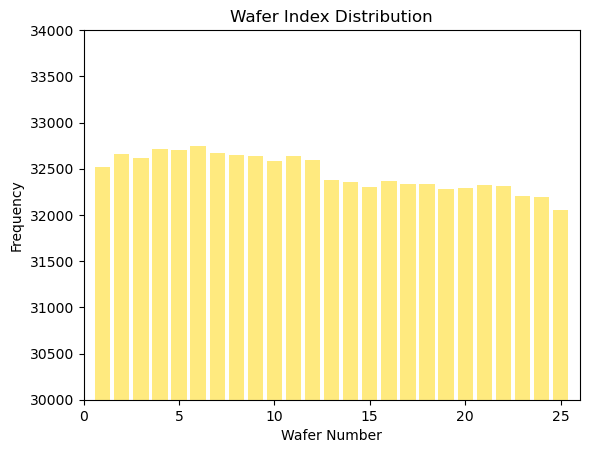

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Wafer Map 데이터 불러오기
df = pd.read_pickle("./WM811K.pkl")

# Wafer 번호별 빈도 계산
uni_Index = np.unique(df.waferIndex, return_counts=True)

# 막대그래프
plt.bar(
    uni_Index[0],
    uni_Index[1],
    color='gold',
    align='center',
    alpha=0.5
)

plt.title("Wafer Index Distribution")
plt.xlabel("Wafer Number")
plt.ylabel("Frequency")

# PPT 원본과 동일한 축 범위
plt.xlim(0, 26)
plt.ylim(30000, 34000)

plt.show()

========== Wafer Map 데이터 ==========
전체 Wafer 개수: 811457

========== Failure Type 종류 ==========
['0' 'Center' 'Donut' 'Edge-Loc' 'Edge-Ring' 'Loc' 'Near-full' 'Random'
 'Scratch' 'none']
Failure Type 종류 개수: 10

========== Failure Type별 데이터 개수 ==========
failureType
0            638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

========== Failure Type별 비율 ==========
0: 78.69%
none: 18.17%
Edge-Ring: 1.19%
Edge-Loc: 0.64%
Center: 0.53%
Loc: 0.44%
Scratch: 0.15%
Random: 0.11%
Donut: 0.07%
Near-full: 0.02%

========== Train/Test Label 종류 ==========
['0' 'Test' 'Training']

========== Train/Test Label별 데이터 개수 ==========
trainTestLabel
0           638507
Test        118595
Training     54355
Name: count, dtype: int64


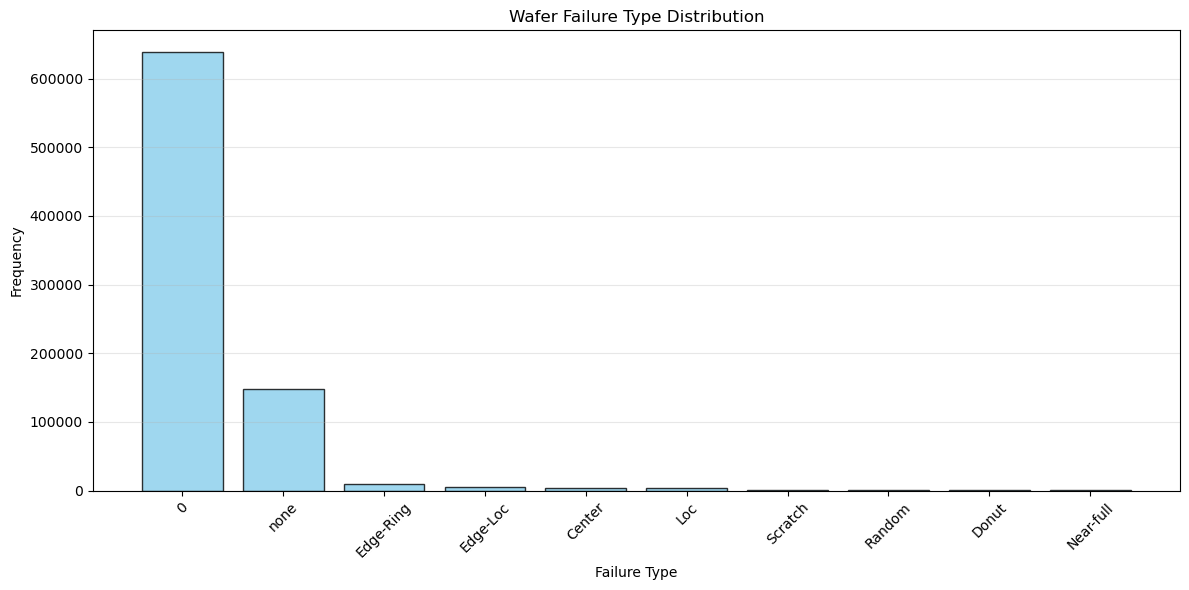

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Wafer Map 데이터 불러오기
df = pd.read_pickle("./WM811K.pkl")

print("========== Wafer Map 데이터 ==========")
print("전체 Wafer 개수:", len(df))

# 2. failureType 데이터 정리
# WM811K는 라벨이 리스트/배열 형태로 저장될 수 있음
def get_label(x):
    if isinstance(x, (list, np.ndarray)):
        if len(x) == 0:
            return "Unknown"
        return str(x[0])

    if pd.isna(x):
        return "Unknown"

    return str(x)

failure = df["failureType"].apply(get_label)
train_test = df["trainTestLabel"].apply(get_label)

# 3. Failure Type 종류 확인
print("\n========== Failure Type 종류 ==========")

failure_types = np.unique(failure)

print(failure_types)
print("Failure Type 종류 개수:", len(failure_types))

# 4. Failure Type별 데이터 개수
print("\n========== Failure Type별 데이터 개수 ==========")

failure_count = failure.value_counts()

print(failure_count)

# 5. Failure Type별 비율 계산
print("\n========== Failure Type별 비율 ==========")

failure_ratio = failure.value_counts(normalize=True) * 100

for name, ratio in failure_ratio.items():
    print(f"{name}: {ratio:.2f}%")

# 6. Train/Test Label 종류 확인
print("\n========== Train/Test Label 종류 ==========")

print(np.unique(train_test))

# 7. Train/Test Label별 데이터 개수
print("\n========== Train/Test Label별 데이터 개수 ==========")

print(train_test.value_counts())

# 8. Failure Type 분포 그래프
plt.figure(figsize=(12, 6))

plt.bar(
    failure_count.index,
    failure_count.values,
    color='skyblue',
    edgecolor='black',
    alpha=0.8
)

plt.title("Wafer Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

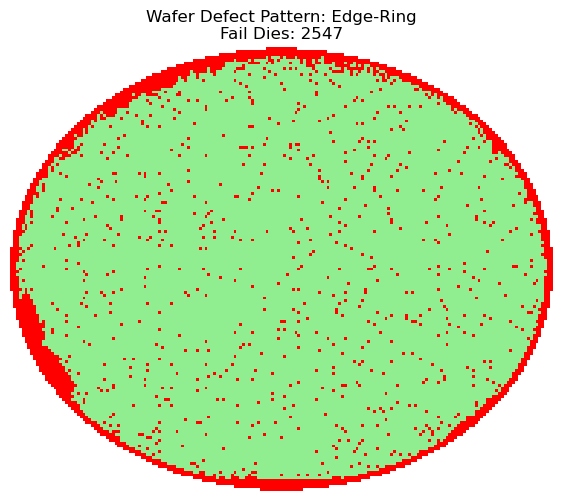

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# 1. 데이터 불러오기
df = pd.read_pickle("./WM811K.pkl")

# 2. Failure Type 정리
def get_label(x):
    if isinstance(x, (list, np.ndarray)):
        if len(x) == 0:
            return "Unknown"
        return str(x[0])
    return str(x)

df["failure_label"] = df["failureType"].apply(get_label)

# 3. 보고 싶은 불량 패턴 선택
target_type = "Edge-Ring"

# 해당 불량 유형의 Wafer 추출
selected = df[df["failure_label"] == target_type].copy()

if selected.empty:
    print("해당 불량 유형의 Wafer가 없습니다.")

else:
    # 4. 각 Wafer의 불량 Die 개수 계산
    selected["fail_count"] = selected["waferMap"].apply(
        lambda x: np.sum(np.asarray(x) == 2)
    )

    # 불량 Die가 가장 많은 Wafer 선택
    wafer = selected.sort_values(
        "fail_count", ascending=False
    ).iloc[0]

    wafer_map = np.asarray(wafer["waferMap"])

    # 5. Wafer Map 시각화
    cmap = ListedColormap([
        "white",       # 0: Wafer 외부
        "lightgreen",  # 1: 정상 Die
        "red"          # 2: 불량 Die
    ])

    norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

    plt.figure(figsize=(7, 7))

    plt.imshow(
        wafer_map,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    plt.title(
        f"Wafer Defect Pattern: {target_type}\n"
        f"Fail Dies: {wafer['fail_count']}"
    )

    plt.axis("off")
    plt.show()

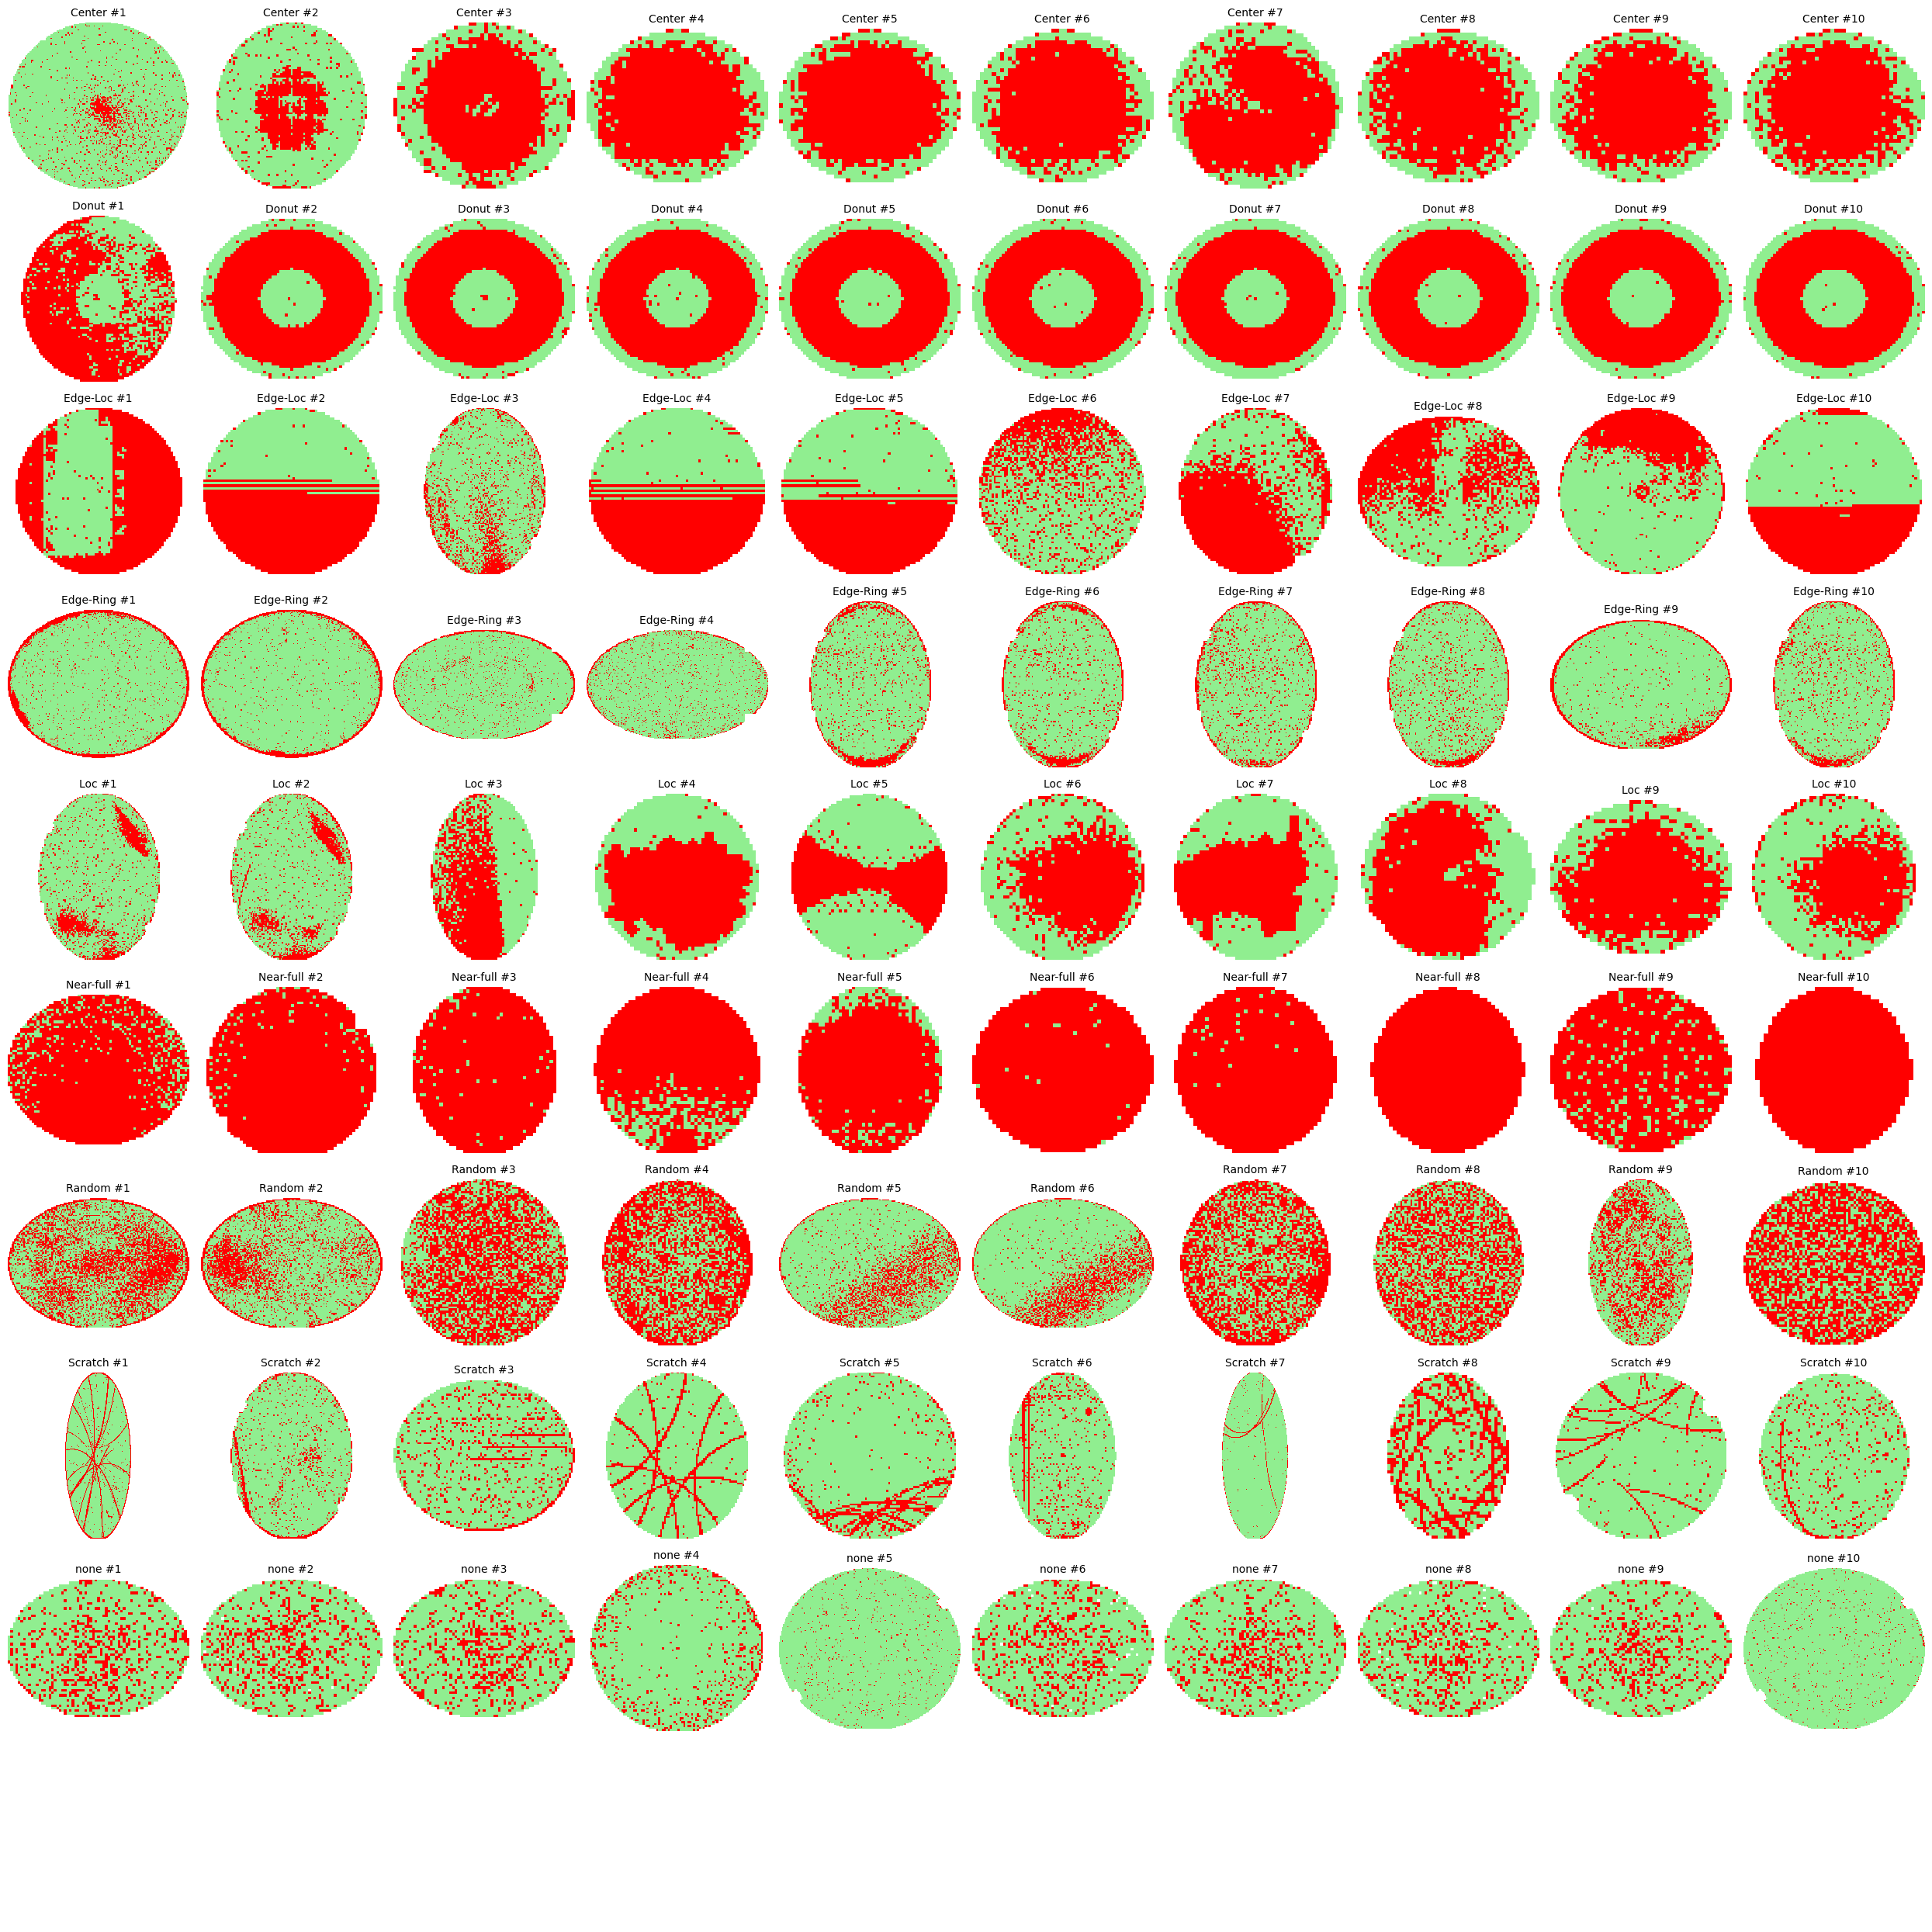

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# 1. 데이터 불러오기
df = pd.read_pickle("./WM811K.pkl")

# 2. Failure Type 정리
def get_label(x):
    if isinstance(x, (list, np.ndarray)):
        if len(x) == 0:
            return "Unknown"
        return str(x[0])

    if pd.isna(x):
        return "Unknown"

    return str(x)

df["failure_label"] = df["failureType"].apply(get_label)

# 3. 출력할 Failure Type
failure_types = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
    "none",
    "Unknown"
]

# 4. Wafer Map 색상 설정
cmap = ListedColormap(["white", "lightgreen", "red"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

# 5. 10행 x 10열 그래프 생성
fig, ax = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(25, 25)
)

# 6. 각 유형별 Wafer 10개 출력
for i, failure_type in enumerate(failure_types):

    # 해당 유형 데이터 선택
    selected = df[
        df["failure_label"] == failure_type
    ].copy()

    # 불량 Die 개수 계산
    selected["fail_count"] = selected["waferMap"].apply(
        lambda x: np.sum(np.asarray(x) == 2)
    )

    # 불량 Die 개수가 많은 순서로 정렬
    selected = selected.sort_values(
        "fail_count",
        ascending=False
    ).head(10)

    # Wafer Map 출력
    for j in range(10):

        ax[i, j].axis("off")

        if j < len(selected):
            wafer_map = np.asarray(
                selected.iloc[j]["waferMap"]
            )

            ax[i, j].imshow(
                wafer_map,
                cmap=cmap,
                norm=norm,
                interpolation="nearest"
            )

            ax[i, j].set_title(
                f"{failure_type} #{j+1}",
                fontsize=10
            )

plt.tight_layout()
plt.show()

실제 불량 패턴 Wafer 개수: 25519
failure_label
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64


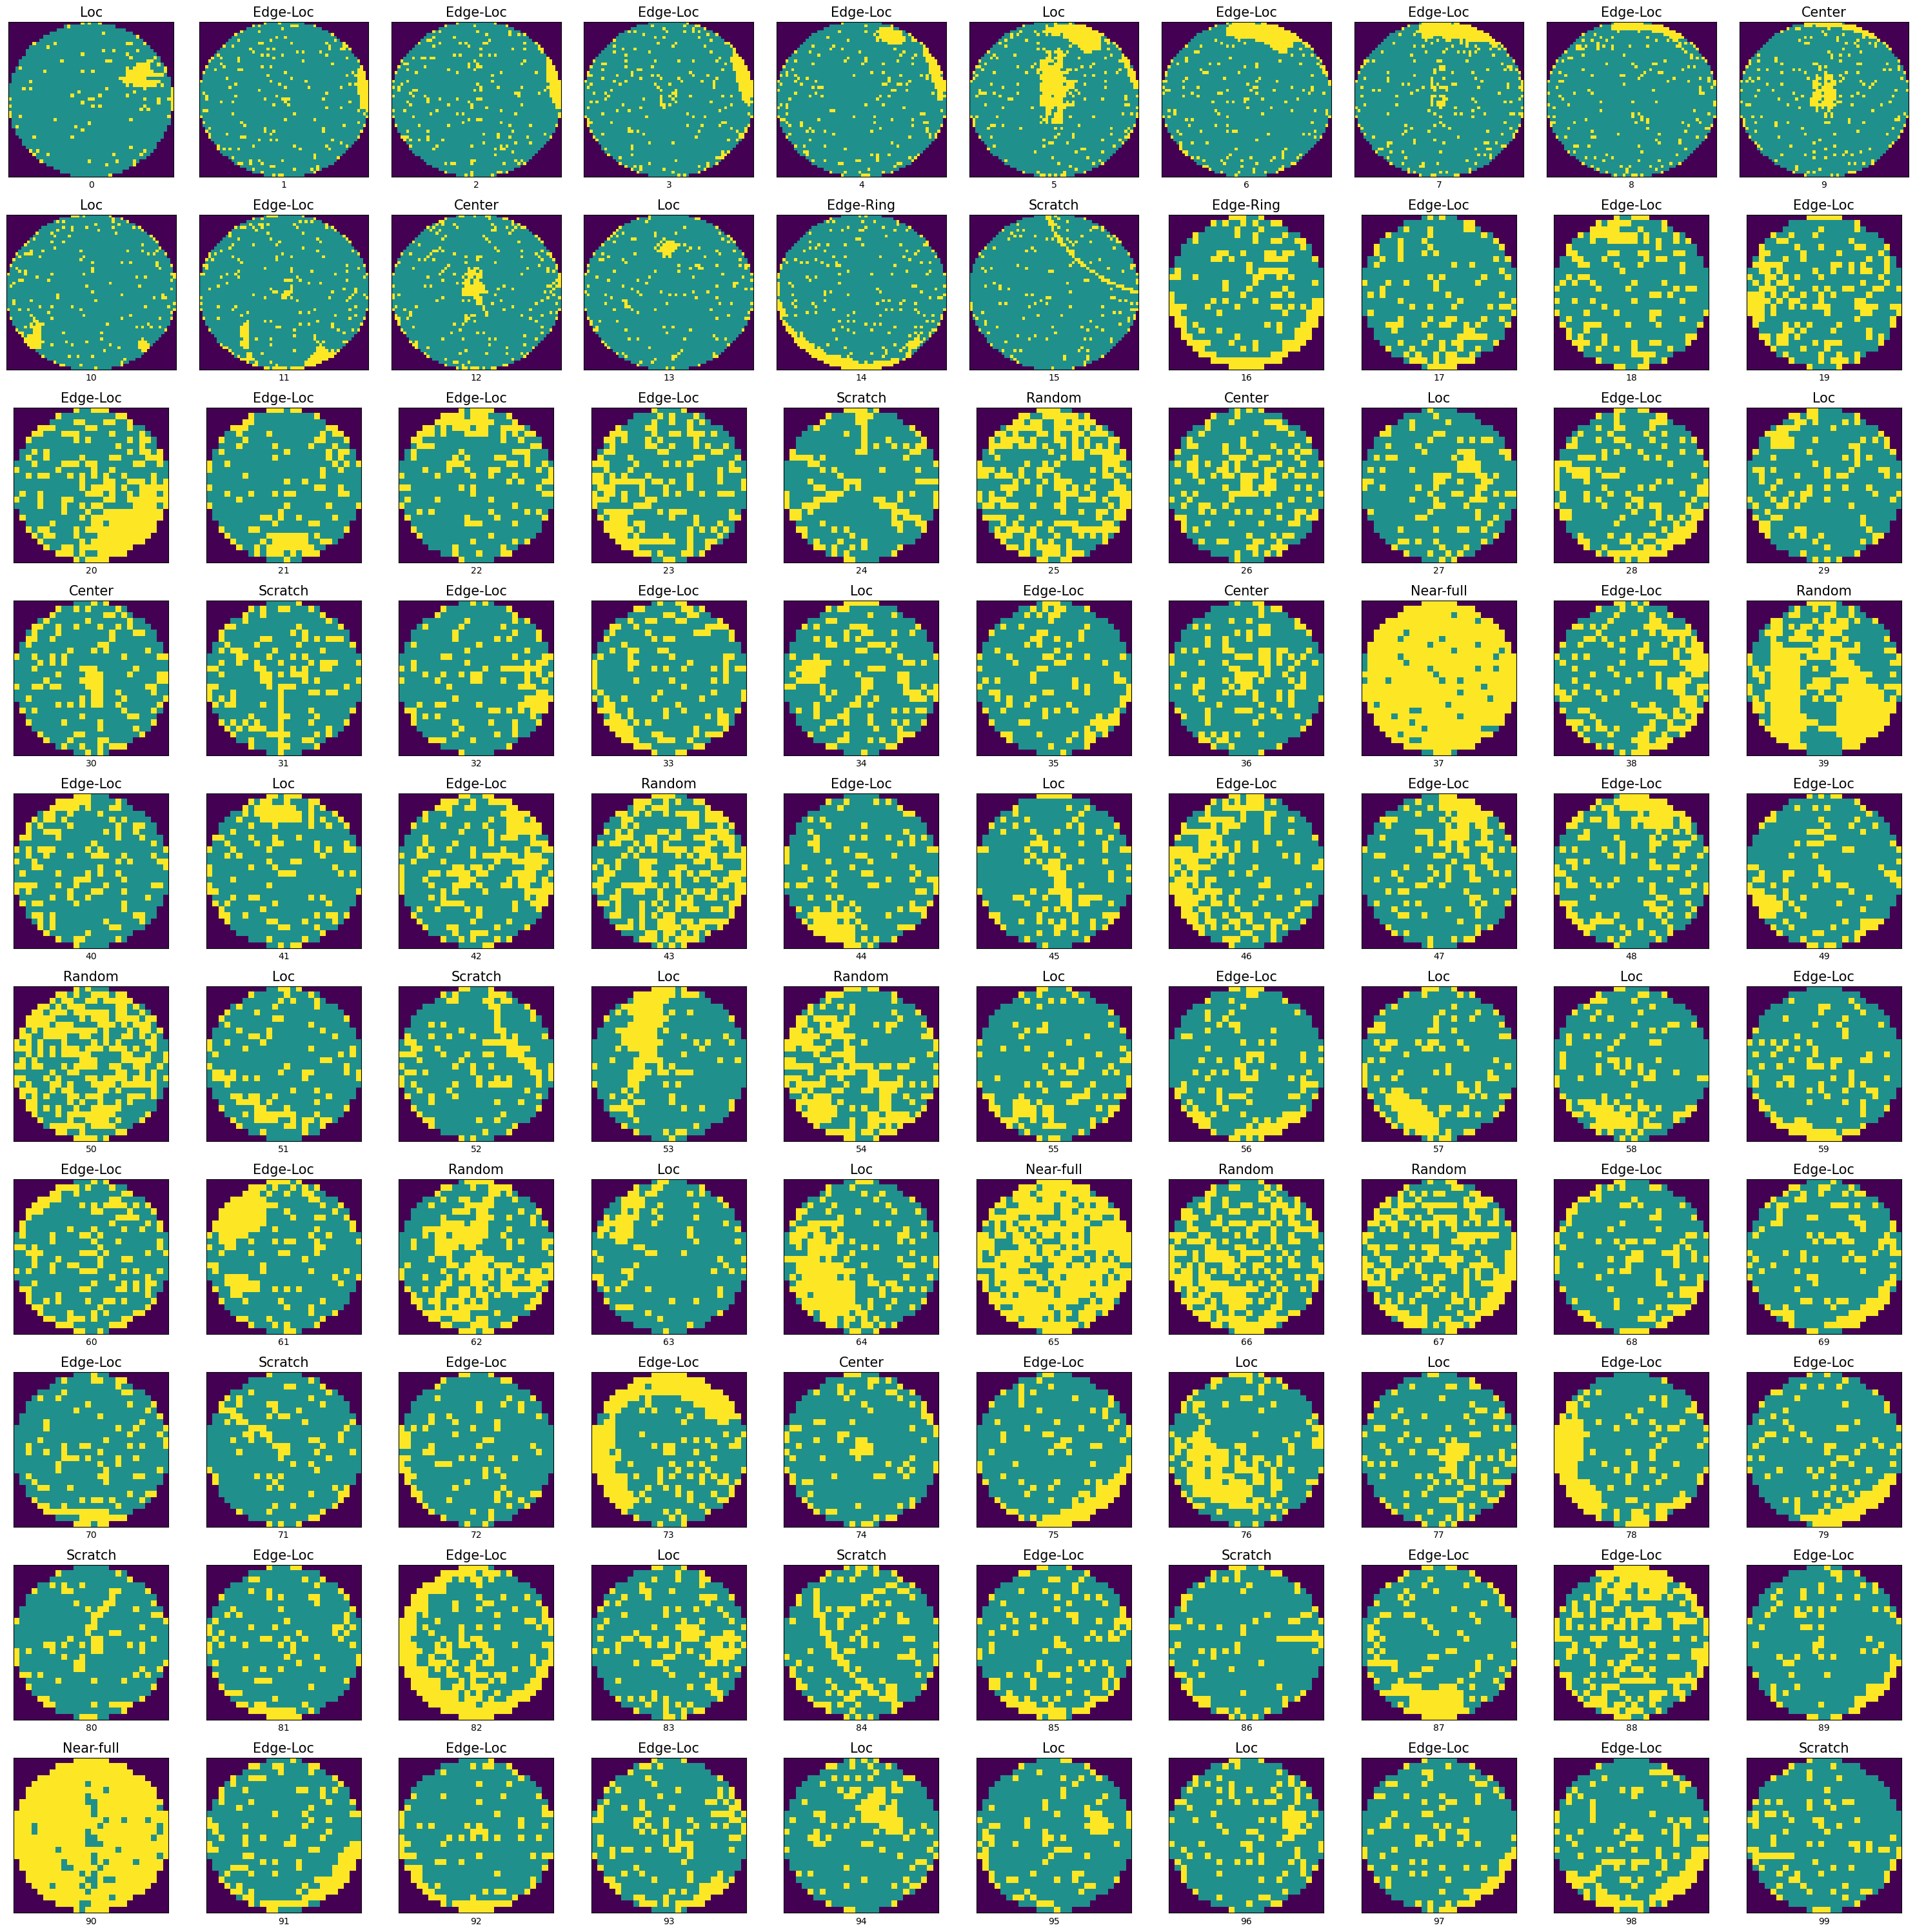

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 데이터 불러오기
df = pd.read_pickle("./WM811K.pkl")

# 2. Failure Type 정리
def get_label(x):
    if isinstance(x, (list, np.ndarray)):
        if len(x) == 0:
            return "Unknown"
        return str(x[0])

    if pd.isna(x):
        return "Unknown"

    return str(x)

df["failure_label"] = df["failureType"].apply(get_label)

# 3. 실제 불량 패턴 종류
failure_types = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

# 4. 실제 불량 패턴이 있는 Wafer만 선택
df_withpattern = df[
    df["failure_label"].isin(failure_types)
].copy()

# 불량 Die(값 2)가 존재하는 Wafer만 선택
df_withpattern = df_withpattern[
    df_withpattern["waferMap"].apply(
        lambda x: np.any(np.asarray(x) == 2)
    )
].reset_index(drop=True)

# 5. 데이터 개수 확인
print("실제 불량 패턴 Wafer 개수:", len(df_withpattern))
print(df_withpattern["failure_label"].value_counts())

# 6. PPT 32페이지처럼 10행 × 10열 생성
fig, ax = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(30, 30)
)

ax = ax.ravel(order="C")

# 7. 실제 불량 패턴 Wafer 100개 출력
for i in range(min(100, len(df_withpattern))):

    img = df_withpattern["waferMap"].iloc[i]

    ax[i].imshow(img)

    ax[i].set_title(
        df_withpattern["failure_label"].iloc[i],
        fontsize=15
    )

    ax[i].set_xlabel(i, fontsize=10)
    ax[i].set_xticks([])
    ax[i].set_yticks([])

# 데이터가 100개보다 적으면 남은 영역 숨기기
for i in range(min(100, len(df_withpattern)), 100):
    ax[i].axis("off")

plt.tight_layout()
plt.show()